In [2]:
import numpy as np
import pandas as pd

#modules for statistics
import statistics
# from scipy import stats

# Mean, Median, Mode, and Central Tendency
mean = average, balance point = sum of all the numbers/total number of values = arithmetic mean

median = middle number when all the values are put in order. If there is an odd number of values, the median is one number. If there is an even number of numbers, you take the middle two and average them. Outliers do not impact the median very much.

mode = number that occurs most often

Central Tendency = a single value that attempts to describe the whole dataset. This number represents the middle or center of its distribution

In [3]:
belize_listings_path = "belize_airbnb_listings.csv"
belize_df = pd.read_csv(belize_listings_path)
belize_df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,36666,Mo's Cozy Casa w/ veranda & access to dock,157752,Monique,Belize,Belize Islands,17.74786,-88.02398,Entire home/apt,141,3,250,2/23/2021,2.00,5,225
1,36690,Mo's Cozy Cabana w/ comfy veranda & access to ...,157752,Monique,Belize,Belize Islands,17.74832,-88.02474,Entire home/apt,71,3,316,2/19/2021,2.46,5,164
2,108932,Purple House eco solar w/ ocean & wildlife views,563377,Michael,Belize,Belize Islands,17.73221,-88.03824,Entire home/apt,191,2,30,3/14/2020,0.78,1,364
3,110483,Michelo's fuchsia suite,567809,Michel,Stann Creek,Stann Creek Mainland,16.52114,-88.36926,Hotel room,121,1,27,2/24/2020,0.29,3,331
4,120115,Seaside Villas Second Floor Unit #4,604999,Bobbi,Belize,Belize Islands,17.74166,-88.02395,Entire home/apt,343,1,30,3/18/2020,0.64,22,203


In [ ]:
belize_df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,2.796000e+03,2.796000e+03,2796.000000,2796.000000,2796.000000,2796.000000,2796.000000,1810.000000,2796.000000,2796.000000
mean,2.792490e+07,1.240278e+08,17.448295,-88.292035,357.102289,2.263948,14.453505,0.538088,22.848355,280.315451
std,1.288964e+07,1.018001e+08,0.537440,0.383876,563.124825,5.669843,30.327768,0.662154,51.711183,120.617632
min,3.666600e+04,1.507890e+05,16.079260,-89.150680,20.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,1.870854e+07,4.389292e+07,17.129573,-88.371015,135.000000,1.000000,0.000000,0.110000,2.000000,221.000000
50%,2.891586e+07,9.171577e+07,17.735145,-88.205560,220.000000,2.000000,2.000000,0.275000,6.000000,349.000000
75%,3.977962e+07,1.875677e+08,17.913837,-87.973793,394.250000,3.000000,13.000000,0.700000,14.000000,364.000000
max,4.833222e+07,3.890334e+08,18.468140,-87.593140,11788.000000,180.000000,316.000000,5.920000,204.000000,365.000000


In [8]:
belize_df[["price","minimum_nights","number_of_reviews"]].mode()

,price,minimum_nights,number_of_reviews
0,151,1.0,0.0
1,252,NaN,NaN


In [11]:
! pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 43.6 MB/s  0:00:00m0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 39.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 40.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


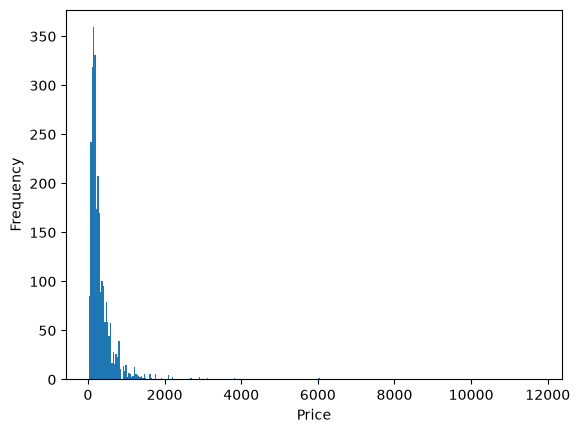

In [ ]:
# from PIL import Image
import matplotlib.pyplot as plt

# histogram is just looking at frequency, so we dont need a y axis
plt.hist(belize_df["price"], bins='auto')
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()
# right-skewed distribution is common for price data


In [ ]:
# mean, median, mode of price
print(belize_df["price"].mean())
print(belize_df["price"].median())
print(belize_df["price"].mode())
# mode is the peak, median is after the peak in a right-skewed distribution
# mean is further to the right, pulled by extreme values

357.1022889842632
220.0
0    151
1    252
Name: price, dtype: int64


# Variance
Variance measures how dispersed data points are from the mean. Low variance means the data points are tightly clusters around the mean. High variance means the data points are spread out from the mean.

Variance is like saying the data points are on average X away from the mean.

Variance of 0 means that all the data points are the same (at least on the metric were looking at variance of)

Degrees of freedom = number of indepedent pieces of information (some nuance depending on the specific statistical analysis)
- product of rows and columns

In [16]:
def variance(data, ddof=0):
    """
    ddof = Delta Degrees of Freedom, used to adjust 
    the divisor in the variance calculation. 
    For population variance, ddof=0. 
    For sample variance, ddof=1.
    """
    n = len(data)
    mean = sum(data) / n
    return sum((x - mean) ** 2 for x in data) / (n - ddof)

In [ ]:
# variance - 1 DOF if a sample, 0 DOF if a population
print(variance(belize_df["price"], ddof=1))  # sample variance
print(variance(belize_df["price"], ddof=0))  # population variance

# if we use sample or population depends on
# how we phrase the question about the data. 
# if we want to ask about all short term rentals in Belize
# we are looking at a sample, but if we specifically
# care about AirBnB listings specifically, 
# we are looking at a population.

317109.56806631474
316996.1526270922


In [18]:
statistics.pvariance(belize_df["price"])

316996.15262709244

In [19]:
statistics.variance(belize_df["price"])

317109.568066315

# Standard Deviation

Standard deviation is the square root of variance

Why? Because square dollars (or other units) often dont make sense. Its hard to have an intuitive understanding of what variance and its square units mean, so we need to use units that make sense to us. We need to get rid of the squared value so we can have an understanding of what we're talking about.

Tells us how far, on average, each value lies from the mean.

In [20]:
#population standard deviation
statistics.pstdev(belize_df["price"])


563.0241137172478

In [21]:
# sample standard deviation
statistics.stdev(belize_df["price"])

563.1248245871558

In [22]:
# aggregate function
belize_df["price"].agg(["mean", "std"])

mean    357.102289
std     563.124825
Name: price, dtype: float64

# Covariance and Correlation

Covariance is to correlation what variance is to standard devation

Covariance tells us how much and to what extent two random variables change together. How much one variable changes as another variable changes.

Positive = variables change in the same direction

Negative = Variables change variables change in the opposite direction

Correlation tells us how strong the relationship is between the variables

correlation = (covariance of x and y)/((standard deviation of x)(standard deviation of y))

In [24]:
np.cov(belize_df["minimum_nights"], belize_df["price"])

# grid generated:
# [variance of x, covariance of x and y]
# [covariance of y and x, variance of y]
# since covariance is positive,
# as minimum_nights increases, price does too
# larger covariance does not necessarily mean
# stronger linear relationship. Its very dependent 
# on the units

array([[3.21471220e+01, 8.90076961e+01],
       [8.90076961e+01, 3.17109568e+05]])

In [ ]:
# Pearson correlation coefficient = -1 to 1 are valid
# -1 indicates perfect negative linear relationship
# 0 indicates no linear relationship
# 1 indicates perfect positive linear relationship
np.corrcoef(belize_df["minimum_nights"], belize_df["price"])
 #matrix of correlation coefficients:
 # [1, correlation of x and y]
 # [correlation of y and x, 1]

 #this shows a super weak correlation between
 # minimum_nights and price

array([[1.        , 0.02787737],
       [0.02787737, 1.        ]])